<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook9_Metrics_Residuals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Cell 1: setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, precision_score, recall_score, accuracy_score)

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Train:", train.shape, "| lowest G3 in the data:", y.min())

Train: (285, 42) | lowest G3 in the data: 4


In [3]:
# Cell 2: the metrics written by hand, then checked against scikit-learn
def mse_(y, p):  return np.mean((y - p) ** 2)
def rmse_(y, p): return np.sqrt(mse_(y, p))
def mae_(y, p):  return np.mean(np.abs(y - p))
def r2_(y, p):   return 1 - np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2)
def mape_(y, p): return np.mean(np.abs(y - p) / np.abs(y)) * 100

y_demo = np.array([10, 12, 11, 13, 12], dtype=float)
p_demo = np.array([11, 11, 12, 15, 10], dtype=float)

print(f"{'metric':8s}{'by hand':>10s}{'sklearn':>10s}")
print(f"{'MSE':8s}{mse_(y_demo, p_demo):10.4f}{mean_squared_error(y_demo, p_demo):10.4f}")
print(f"{'MAE':8s}{mae_(y_demo, p_demo):10.4f}{mean_absolute_error(y_demo, p_demo):10.4f}")
print(f"{'R2':8s}{r2_(y_demo, p_demo):10.4f}{r2_score(y_demo, p_demo):10.4f}")
print(f"{'RMSE':8s}{rmse_(y_demo, p_demo):10.4f}")

metric     by hand   sklearn
MSE         2.2000    2.2000
MAE         1.4000    1.4000
R2         -1.1154   -1.1154
RMSE        1.4832


In [4]:
# Cell 3: RMSE punishes big misses, MAE does not
actual = np.array([10, 12, 11, 13, 12], dtype=float)
model_a = np.array([11, 13, 12, 14, 13], dtype=float)    # misses by 1 every time
model_b = np.array([10, 12, 11, 13, 17], dtype=float)    # perfect four times, one miss of 5

for name, p in [("Model A (steady small misses)", model_a), ("Model B (one big miss)", model_b)]:
    print(f"{name:32s} MAE = {mae_(actual, p):.2f} | RMSE = {rmse_(actual, p):.2f}")

Model A (steady small misses)    MAE = 1.00 | RMSE = 1.00
Model B (one big miss)           MAE = 1.00 | RMSE = 2.24


In [5]:
# Cell 4: cross-validated predictions for each model and feature set
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),
}
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

preds = {}
for fname, X in feature_sets.items():
    for mname, m in models.items():
        preds[(fname, mname)] = cross_val_predict(m, X, y, cv=cv)

rows = []
for (fname, mname), p in preds.items():
    base_mae = mae_(y.values, preds[(fname, "Baseline (mean)")])
    rows.append({"features": fname, "model": mname,
                 "MAE": round(mae_(y.values, p), 3),
                 "RMSE": round(rmse_(y.values, p), 3),
                 "R2": round(r2_(y.values, p), 3),
                 "scaled MAE": round(mae_(y.values, p) / base_mae, 3)})
metrics = pd.DataFrame(rows)
metrics

,features,model,MAE,RMSE,R2,scaled MAE
0,early (no G1/G2),Baseline (mean),2.655,3.257,-0.003,1.000
1,early (no G1/G2),Linear,2.439,3.057,0.117,0.919
2,early (no G1/G2),Ridge,2.398,2.962,0.170,0.903
3,all features,Baseline (mean),2.655,3.257,-0.003,1.000
4,all features,Linear,0.743,0.909,0.922,0.280
5,all features,Ridge,0.739,0.906,0.922,0.278


In [6]:
# Cell 5: why MAPE is a poor choice here
y_zero = np.array([0, 8, 12, 15], dtype=float)
p_zero = np.array([1, 9, 11, 14], dtype=float)           # every prediction misses by exactly 1
with np.errstate(divide="ignore"):
    print("Percentage errors when one student scored 0:", np.abs(y_zero - p_zero) / np.abs(y_zero))

print("\nThe same 1-point miss, at different grades:")
for g in [5, 8, 12, 18]:
    print(f"  grade {g:2d}: {100 / g:5.1f}% error")

best = preds[("all features", "Ridge")]
print("\nOn our cleaned data (Ridge, all features):")
print(f"  MAE  = {mae_(y.values, best):.2f} grade points")
print(f"  MAPE = {mape_(y.values, best):.1f}%  <- pulled up by the low-grade students")

Percentage errors when one student scored 0: [       inf 0.125      0.08333333 0.06666667]

The same 1-point miss, at different grades:
  grade  5:  20.0% error
  grade  8:  12.5% error
  grade 12:   8.3% error
  grade 18:   5.6% error

On our cleaned data (Ridge, all features):
  MAE  = 0.74 grade points
  MAPE = 7.2%  <- pulled up by the low-grade students


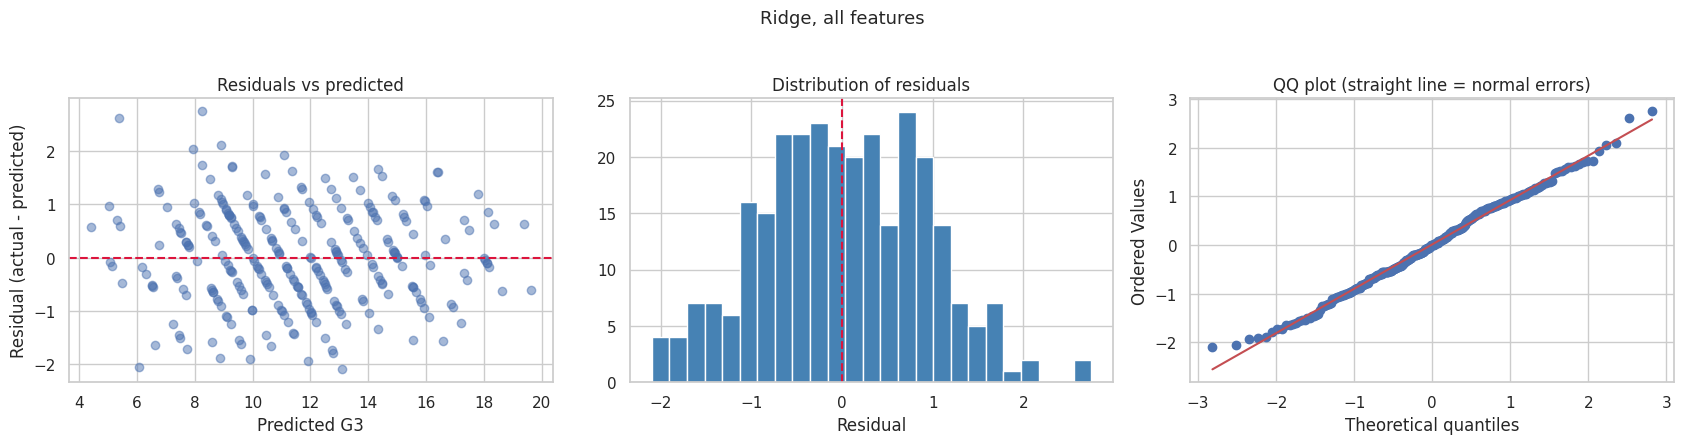

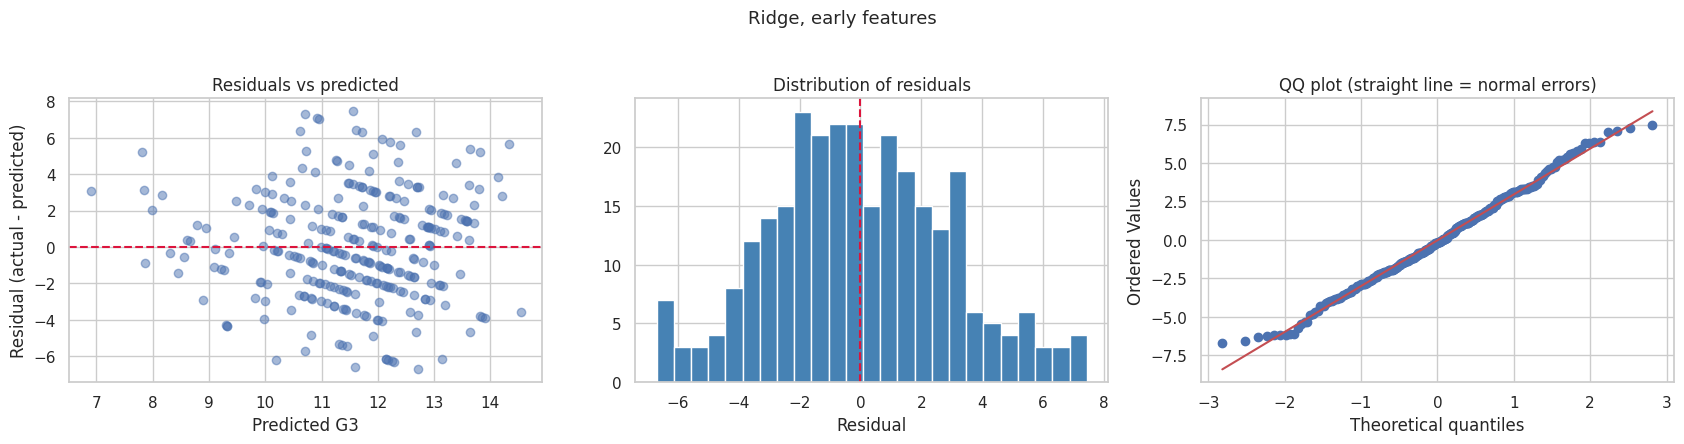

In [7]:
# Cell 6: residual diagnostics, three plots per model
def residual_plots(p, title, fname):
    resid = y.values - p
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))

    axes[0].scatter(p, resid, alpha=0.5)
    axes[0].axhline(0, color="crimson", linestyle="--")
    axes[0].set_xlabel("Predicted G3"); axes[0].set_ylabel("Residual (actual - predicted)")
    axes[0].set_title("Residuals vs predicted")

    axes[1].hist(resid, bins=25, color="steelblue", edgecolor="white")
    axes[1].axvline(0, color="crimson", linestyle="--")
    axes[1].set_xlabel("Residual"); axes[1].set_title("Distribution of residuals")

    stats.probplot(resid, dist="norm", plot=axes[2])
    axes[2].set_title("QQ plot (straight line = normal errors)")

    fig.suptitle(title, y=1.03, fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

residual_plots(preds[("all features", "Ridge")], "Ridge, all features", "residuals_all.png")
residual_plots(preds[("early (no G1/G2)", "Ridge")], "Ridge, early features", "residuals_early.png")

In [8]:
# Cell 7: where does the model fail? Error by grade band
bands = pd.cut(y, bins=[0, 7, 9, 12, 15, 20],
               labels=["4-7", "8-9", "10-12", "13-15", "16-20"])

def band_table(p):
    d = pd.DataFrame({"band": bands, "resid": y.values - p})
    return d.groupby("band", observed=True)["resid"].agg(
        n="count",
        mean_resid="mean",
        MAE=lambda r: r.abs().mean()).round(2)

print("ALL FEATURES (Ridge):")
print(band_table(preds[("all features", "Ridge")]))
print("\nEARLY FEATURES (Ridge):")
print(band_table(preds[("early (no G1/G2)", "Ridge")]))

ALL FEATURES (Ridge):
         n  mean_resid   MAE
band                        
4-7     25       -0.59  0.84
8-9     48       -0.16  0.75
10-12  109        0.01  0.77
13-15   69        0.17  0.64
16-20   34        0.41  0.73

EARLY FEATURES (Ridge):
         n  mean_resid   MAE
band                        
4-7     25       -4.78  4.78
8-9     48       -2.43  2.46
10-12  109       -0.66  1.33
13-15   69        1.99  1.99
16-20   34        4.81  4.81


In [9]:
# Cell 8: do errors differ across groups? (an early look at fairness, done properly in Phase 5)
groups = {
    "sex (0=F, 1=M)": X_all["sex"],
    "school (0=GP, 1=MS)": X_all["school"],
    "address (0=rural, 1=urban)": X_all["address"],
    "has past failures": (X_all["failures"] > 0).astype(int),
    "wants higher education": X_all["higher"],
}

rows = []
for gname, col in groups.items():
    for val in sorted(col.unique()):
        mask = (col == val).values
        for fname in ["early (no G1/G2)", "all features"]:
            resid = y.values[mask] - preds[(fname, "Ridge")][mask]
            rows.append({"group": gname, "value": val, "n": mask.sum(), "features": fname,
                         "mean residual": round(resid.mean(), 2),
                         "MAE": round(np.abs(resid).mean(), 2)})
group_table = pd.DataFrame(rows)
group_table.pivot_table(index=["group", "value", "n"], columns="features",
                        values=["mean residual", "MAE"])

MAE                   \
features                             all features early (no G1/G2)   
group                      value n                                   
address (0=rural, 1=urban) 0     63          0.70             2.38   
                           1     222         0.75             2.40   
has past failures          0     233         0.74             2.45   
                           1     52          0.73             2.16   
school (0=GP, 1=MS)        0     252         0.73             2.42   
                           1     33          0.80             2.24   
sex (0=F, 1=M)             0     148         0.77             2.37   
                           1     137         0.71             2.43   
wants higher education     0     12          0.61             1.65   
                           1     273         0.74             2.43   

                                     mean residual                   
features                              all features early (no G1/G2)  
group                      value n                                   
address (0=rural, 1=urban) 0     63          -0.03            -0.13  
                           1     222          0.03             0.01  
has past failures          0     233          0.02             0.09  
                           1     52          -0.02            -0.52  
school (0=GP, 1=MS)        0     252          0.01             0.00  
                           1     33           0.02            -0.20  
sex (0=F, 1=M)             0     148          0.00            -0.13  
                           1     137          0.02             0.09  
wants higher education     0     12           0.12            -0.20  
                           1     273          0.01            -0.02

In [10]:
# Cell 9: at-risk detection, flag students predicted to score below 10
y_fail = (y < 10).astype(int).values
print(f"Students who actually scored below 10: {y_fail.sum()} of {len(y)} ({y_fail.mean():.1%})")

rows = []
for fname in ["early (no G1/G2)", "all features"]:
    flag = (preds[(fname, "Ridge")] < 10).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_fail, flag).ravel()
    rows.append({"features": fname, "flagged": flag.sum(),
                 "caught (TP)": tp, "missed (FN)": fn, "false alarms (FP)": fp,
                 "accuracy": round(accuracy_score(y_fail, flag), 3),
                 "precision": round(precision_score(y_fail, flag, zero_division=0), 3),
                 "recall": round(recall_score(y_fail, flag, zero_division=0), 3)})

nobody = np.zeros_like(y_fail)
rows.append({"features": "flag nobody", "flagged": 0, "caught (TP)": 0,
             "missed (FN)": y_fail.sum(), "false alarms (FP)": 0,
             "accuracy": round(accuracy_score(y_fail, nobody), 3),
             "precision": np.nan, "recall": 0.0})
pd.DataFrame(rows)

Students who actually scored below 10: 73 of 285 (25.6%)


,features,flagged,caught (TP),missed (FN),false alarms (FP),accuracy,precision,recall
0,early (no G1/G2),34,20,53,14,0.765,0.588,0.274
1,all features,102,71,2,31,0.884,0.696,0.973
2,flag nobody,0,0,73,0,0.744,NaN,0.000


In [11]:
# Cell 10: save the results for the final report
metrics.to_csv("metrics_cv.csv", index=False)

out = X_all.copy()
out["G3"] = y
for (fname, mname), p in preds.items():
    out[f"pred_{fname.split()[0]}_{mname.split()[0]}"] = p
out.to_csv("cv_predictions.csv", index=False)
print("Saved metrics_cv.csv and cv_predictions.csv")
print(metrics.to_string(index=False))

Saved metrics_cv.csv and cv_predictions.csv
        features           model   MAE  RMSE     R2  scaled MAE
early (no G1/G2) Baseline (mean) 2.655 3.257 -0.003       1.000
early (no G1/G2)          Linear 2.439 3.057  0.117       0.919
early (no G1/G2)           Ridge 2.398 2.962  0.170       0.903
    all features Baseline (mean) 2.655 3.257 -0.003       1.000
    all features          Linear 0.743 0.909  0.922       0.280
    all features           Ridge 0.739 0.906  0.922       0.278
